In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#clean styling for figures
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

#load the data path
data_path = "./Kamilimu_Case_Study_Dataset/Sierra Leone/labeled_power_source_data.csv"
df = pd.read_csv(data_path)


In [2]:
#inspecting the schema and data structure
print(f"Dataset shape: {df.shape[0]:,} rows and {df.shape[1]:,} columns")
#This tells us the total rows and columns
# df.info() tells us the data type of each column and non-null count.
print("--- Column Details ---")
print(df.info())

# Show the first 5 rows to visually understand the records
print("\n--- First 5 Records ---")
print(df.head())

Dataset shape: 5,125,181 rows and 9 columns
--- Column Details ---
<class 'pandas.DataFrame'>
RangeIndex: 5125181 entries, 0 to 5125180
Data columns (total 9 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   Unnamed: 0               int64  
 1   respondent_id            str    
 2   time                     str    
 3   site_id                  str    
 4   room                     str    
 5   voltage                  float64
 6   frequency                float64
 7   available_power_sources  str    
 8   active_power_source      str    
dtypes: float64(2), int64(1), str(6)
memory usage: 351.9 MB
None

--- First 5 Records ---
   Unnamed: 0 respondent_id                 time             site_id  \
0           0      37B7AE20  2023-04-25 21:46:10  princess_christian   
1           1      3393AD1E  2023-04-25 21:46:03  princess_christian   
2           2      358F181D  2023-04-25 21:46:03  princess_christian   
3           3      E3670099  2023-04

In [3]:
#identifying meta data columns
print("Summary of unique values in Target")
for col in df.select_dtypes(include=['object','string','str','category']).columns:
    print(f"Value distribution for {col}:")
    print(df[col].value_counts(dropna=False))

Summary of unique values in Target
Value distribution for respondent_id:
respondent_id
285A769C    243190
37B7AE20    234514
31581AC3    232387
40101E61    226917
23D03AB0    223827
E76A2F18    223788
BC894308    222481
36291A37    219468
E3670099    213575
A7081050    211529
CD9B9362    208631
31AA625C    199929
794A4021    197002
7A696BB0    192821
8DF9A946    185702
41570E47    184551
AE9D9E66    183658
7CF431FF    168150
181DEF5E    160227
358F181D    127255
A4DD6DF3    123665
DD49499C    112891
7591C426    107589
95E7399D    101057
9FD654ED     99146
CE9340E1     95834
86ABF063     95481
A45DEF14     82543
30314B82     73686
65E8690F     63932
42D5AFD3     60894
274B46C5     19865
3393AD1E     16067
10DA907C      7443
311723D1      5486
Name: count, dtype: int64
Value distribution for time:
time
2023-07-07 19:20:03    30
2023-07-07 19:24:03    30
2023-07-07 19:22:03    29
2023-07-12 22:02:03    29
2023-06-01 12:32:03    29
                       ..
2024-03-31 16:26:04     1
2024-0

In [4]:
# Check how missing frequencies correspond to voltage and the target label
missing_freq = df[df['frequency'].isna()]
print("When frequency is NaN:")
print(f"Count: {len(missing_freq):,}")
print("Voltage stats:")
print(missing_freq['voltage'].describe())
print("\nActive power sources assigned to NaN frequency:")
print(missing_freq['active_power_source'].value_counts(dropna=False))

df['time']=pd.to_datetime(df['time'])

When frequency is NaN:
Count: 0
Voltage stats:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: voltage, dtype: float64

Active power sources assigned to NaN frequency:
Series([], Name: count, dtype: int64)


In [5]:
# Isolate active power readings with valid ground-truth labels
active_df = df.dropna(subset=['frequency']).copy()
active_df = active_df[active_df['active_power_source'].isin(['grid', 'solar', 'generator'])].copy()
print(f"Clean active rows for EDA and ML: {len(active_df):,}")

Clean active rows for EDA and ML: 5,112,241


In [6]:
# -------------------------------------------------------------
# STEP 3 / PART C: STATISTICAL SPREAD ANALYSIS
# -------------------------------------------------------------

# Quick sanity check on active class counts
print("Active classes being analyzed:")
print(active_df['active_power_source'].value_counts())

# Vectorized aggregation across classes
stats_summary = active_df.groupby('active_power_source').agg(
    count=('frequency', 'count'),
    freq_mean=('frequency', 'mean'),
    freq_std=('frequency', 'std'),
    freq_min=('frequency', 'min'),
    freq_25=('frequency', lambda x: x.quantile(0.25)),
    freq_median=('frequency', 'median'),
    freq_75=('frequency', lambda x: x.quantile(0.75)),
    freq_max=('frequency', 'max'),
    volt_mean=('voltage', 'mean'),
    volt_std=('voltage', 'std'),
    volt_median=('voltage', 'median')
).reset_index()

# Add Interquartile Range (IQR = Q75 - Q25) as a robust volatility metric
stats_summary['freq_iqr'] = stats_summary['freq_75'] - stats_summary['freq_25']

print("\n--- Summary Statistics by Active Power Source ---")
print(stats_summary[['active_power_source', 'count', 'freq_mean', 'freq_std', 'freq_iqr', 'freq_min', 'freq_max', 'volt_mean', 'volt_std']].to_string(index=False))

Active classes being analyzed:
active_power_source
grid         2403874
solar        2160602
generator     547765
Name: count, dtype: int64

--- Summary Statistics by Active Power Source ---
active_power_source   count  freq_mean  freq_std  freq_iqr  freq_min  freq_max  volt_mean  volt_std
          generator  547765  49.688806  3.080240  3.357422 30.038148     100.0 223.161974 16.125773
               grid 2403874  50.161854  1.255480  0.228632 31.013522     100.0 233.352665 12.245248
              solar 2160602  50.010719  0.598411  0.052503 32.222723     100.0 226.747559  9.073986


In [7]:
# 1. Target column identification
target_col = 'active_power_source'

# 2. Filter out ambiguous rows
active_df = df[df[target_col].isin(['grid', 'solar', 'generator'])].copy()

C:\Users\Violet\AppData\Local\Temp\ipykernel_24644\118492103.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


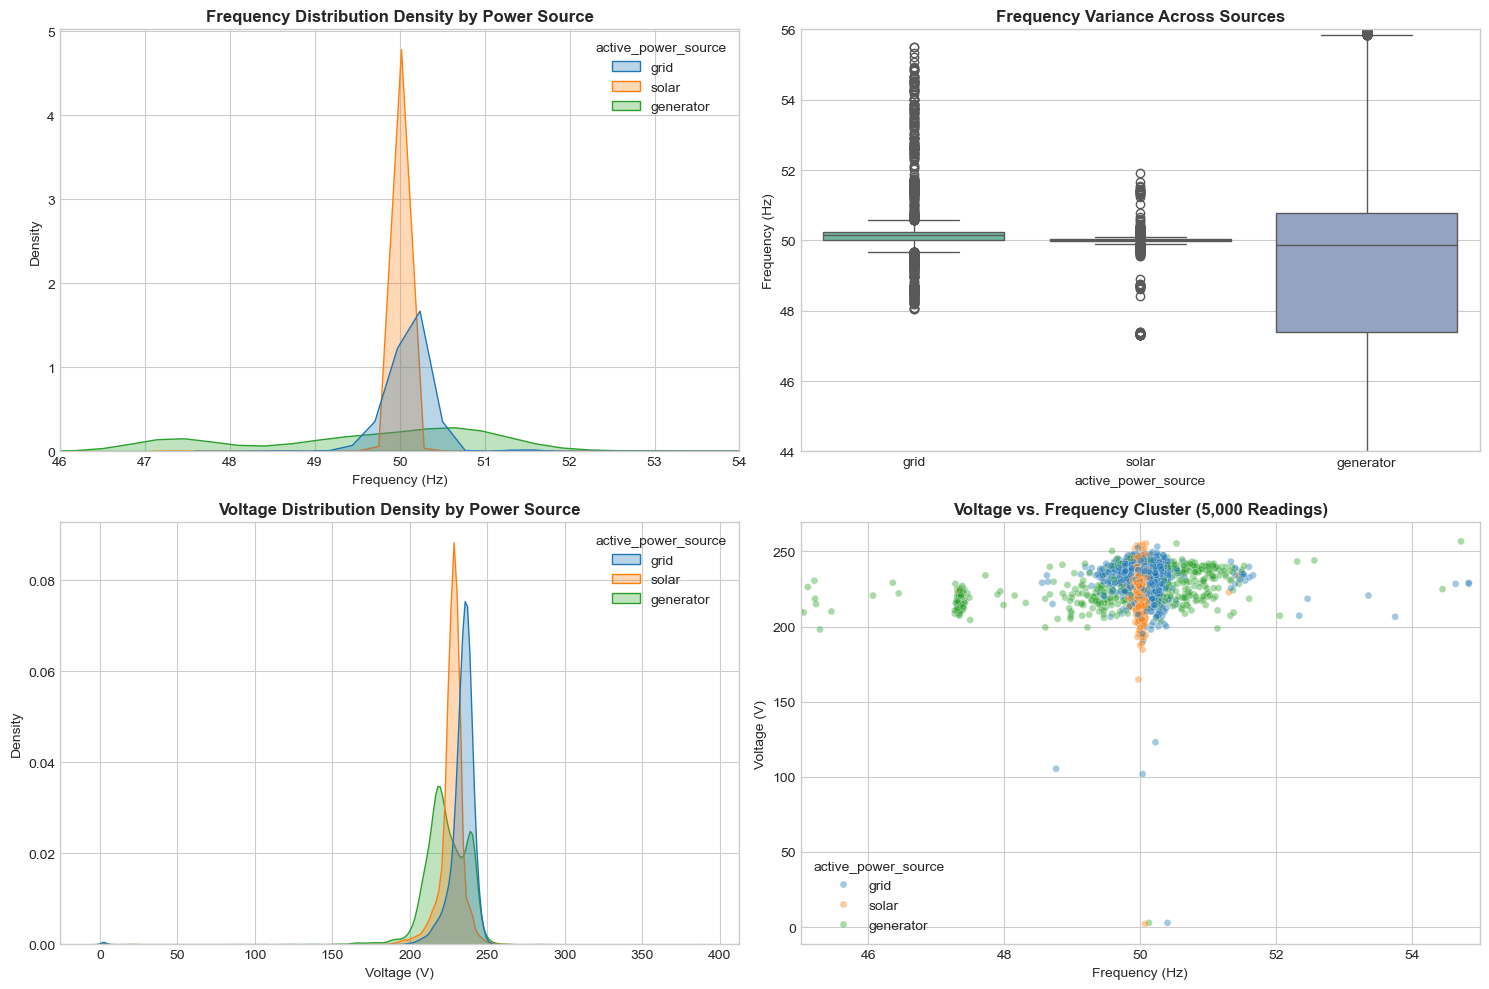

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sample 100,000 rows to make plotting fast and avoid memory lag
plot_sample = active_df.sample(n=100000, random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Frequency Distribution (Density)
sns.kdeplot(
    data=plot_sample, x='frequency', hue=target_col,
    common_norm=False, fill=True, alpha=0.3, ax=axes[0, 0]
)
axes[0, 0].set_title("Frequency Distribution Density by Power Source", fontsize=12, fontweight='bold')
axes[0, 0].set_xlim(46, 54)
axes[0, 0].set_xlabel("Frequency (Hz)")

# 2. Frequency Boxplot (Spread & Outliers)
sns.boxplot(
    data=plot_sample, x=target_col, y='frequency',
    palette='Set2', ax=axes[0, 1]
)
axes[0, 1].set_title("Frequency Variance Across Sources", fontsize=12, fontweight='bold')
axes[0, 1].set_ylim(44, 56)
axes[0, 1].set_ylabel("Frequency (Hz)")

# 3. Voltage Distribution (Density)
sns.kdeplot(
    data=plot_sample, x='voltage', hue=target_col,
    common_norm=False, fill=True, alpha=0.3, ax=axes[1, 0]
)
axes[1, 0].set_title("Voltage Distribution Density by Power Source", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Voltage (V)")

# 4. Voltage vs. Frequency Cluster
sns.scatterplot(
    data=plot_sample.sample(n=5000, random_state=42),
    x='frequency', y='voltage', hue=target_col,
    alpha=0.4, s=25, ax=axes[1, 1]
)
axes[1, 1].set_title("Voltage vs. Frequency Cluster (5,000 Readings)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlim(45, 55)
axes[1, 1].set_xlabel("Frequency (Hz)")
axes[1, 1].set_ylabel("Voltage (V)")

plt.tight_layout()
plt.show()

In [9]:
#prepare time and sort the data by converting time into date time
active_df['time']=pd.to_datetime(active_df['time'])
# sort chronologicallywithin each physical sensor plug
active_df= active_df.sort_values(by=['respondent_id','time']).reset_index(drop= True)
print("Data sorted chronologically per sensor")
print(active_df[['respondent_id','time','frequency','voltage']].head())

Data sorted chronologically per sensor
  respondent_id                time  frequency     voltage
0      10DA907C 2024-03-21 13:38:03  49.756195  231.966054
1      10DA907C 2024-03-21 13:40:03  49.912653  231.258840
2      10DA907C 2024-03-21 13:42:03  49.835543  231.258840
3      10DA907C 2024-03-21 13:44:03  49.905180  231.258840
4      10DA907C 2024-03-21 13:46:03  49.895220  230.551627


In [10]:
#calculate distance from nominal ratings
#frequency far grom 50hz
active_df['freq_dev_50']=(active_df['frequency']-50).abs()
#voltage
active_df['volt_dev_230']=(active_df['voltage']-230).abs()
#hour from timestamp
active_df['hour'] = active_df['time'].dt.hour
#binary flag dt
active_df['is_daytime'] = active_df['hour'].between(7,19).astype(int)

print("Instantaneous and context features created.")
print(active_df[['frequency', 'freq_dev_50', 'voltage', 'volt_dev_230', 'hour', 'is_daytime']].head())


Instantaneous and context features created.
   frequency  freq_dev_50     voltage  volt_dev_230  hour  is_daytime
0  49.756195     0.243805  231.966054      1.966054    13           1
1  49.912653     0.087347  231.258840      1.258840    13           1
2  49.835543     0.164457  231.258840      1.258840    13           1
3  49.905180     0.094820  231.258840      1.258840    13           1
4  49.895220     0.104780  230.551627      0.551627    13           1


In [11]:
#calculating rolling window volatility metrics and jitter
#Rolling window features
WINDOW_SIZE = 7
active_df['freq_diff'] = active_df.groupby('respondent_id')['frequency'].diff().abs()
active_df['volt_diff'] = active_df.groupby('respondent_id')['voltage'].diff().abs()

#rolling window std
active_df['freq_roll_std_15m']=(
    active_df.groupby('respondent_id')['frequency']
    .rolling(window=WINDOW_SIZE, min_periods=3)
    .std()
    .reset_index(level=0, drop=True)
)
active_df['volt_roll_std_15m'] = (
    active_df.groupby('respondent_id')['voltage']
    .rolling(window=WINDOW_SIZE, min_periods=3)
    .std()
    .reset_index(level=0, drop=True)
)

# Rolling Mean Absolute Deviation (MAD) to replicate nLine's baseline metric
rolling_freq_mean = (
    active_df.groupby('respondent_id')['frequency']
    .rolling(window=WINDOW_SIZE, min_periods=3)
    .mean()
    .reset_index(level=0, drop=True)
)

active_df['freq_roll_mad_15m'] = (
    (active_df['frequency'] - rolling_freq_mean).abs()
    .groupby(active_df['respondent_id'])
    .rolling(window=WINDOW_SIZE, min_periods=3)
    .mean()
    .reset_index(level=0, drop=True)
)
# Clean up initial NaN values from window startup (first 2-3 rows per sensor)
engineered_cols = [
    'freq_dev_50', 'volt_dev_230', 'hour', 'is_daytime',
    'freq_diff', 'volt_diff', 'freq_roll_std_15m',
    'volt_roll_std_15m', 'freq_roll_mad_15m'
]
active_df[engineered_cols] = active_df.groupby('respondent_id')[engineered_cols].bfill()
active_df[engineered_cols] = active_df[engineered_cols].fillna(0.0)

print("Rolling features generated and cleaned!")



Rolling features generated and cleaned!


In [12]:
# CELL 4: Verification Summary
check_table = active_df.groupby('active_power_source')[
    ['freq_dev_50', 'freq_diff', 'freq_roll_std_15m', 'freq_roll_mad_15m', 'is_daytime']
].mean()

print("--- Mean Feature Values Across Sources ---")
print(check_table.round(4))

--- Mean Feature Values Across Sources ---
                     freq_dev_50  freq_diff  freq_roll_std_15m  \
active_power_source                                              
generator                 1.8990     0.2331             0.2769   
grid                      0.2442     0.1393             0.1447   
solar                     0.0420     0.0585             0.0640   

                     freq_roll_mad_15m  is_daytime  
active_power_source                                 
generator                       0.2299      0.4716  
grid                            0.1143      0.5326  
solar                           0.0513      0.5865  


In [13]:
%pip install scikit-learn lightgbm

Note: you may need to restart the kernel to use updated packages.


In [14]:
#prepare features, target, and chronological split
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

#define features and target
feature_cols = [
    'frequency', 'voltage',
    'freq_dev_50', 'volt_dev_230', 
    'hour', 'is_daytime', 
    'freq_diff', 'volt_diff', 
    'freq_roll_std_15m', 'volt_roll_std_15m', 
    'freq_roll_mad_15m'
]
target_col = 'active_power_source'

#encode text labels into integers
le = LabelEncoder()
active_df['target_encoded']= le.fit_transform(active_df[target_col])

print("Target encoding mapping")
for idx, label in enumerate(le.classes_):
    print(f"{label} -> {idx}")

#sample 300k chronologically
sample_size = min(300000, len(active_df))
model_subset = active_df.sort_values('time').tail(sample_size).reset_index(drop=True)

#chronological 80/20 splitting
split_idx = int(len(model_subset) * 0.80)

train_data = model_subset.iloc[:split_idx]
test_data = model_subset.iloc[split_idx:]

X_train = train_data[feature_cols]
y_train = train_data['target_encoded']

X_test = test_data[feature_cols]
y_test = test_data['target_encoded']

print(f"\nTraining set size: {len(X_train):,} readings (First 80% of time)")
print(f"Testing set size:  {len(X_test):,} readings (Last 20% of time)")


Target encoding mapping
generator -> 0
grid -> 1
solar -> 2

Training set size: 240,000 readings (First 80% of time)
Testing set size:  60,000 readings (Last 20% of time)


In [15]:
# CELL 6: Model 1 - Logistic Regression Baseline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

#build pipeline first, scale features then fit multinomial regression
lr_pipeline = Pipeline([
    ('scaler',StandardScaler()),
    ('model', LogisticRegression(max_iter=1000,random_state = 42, class_weight='balanced'))
])

print("Training logistic regression baseline model...")
lr_pipeline.fit(X_train, y_train)

#predict on test set
y_pred_lr = lr_pipeline.predict(X_test)

print("\n--- Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred_lr, target_names=le.classes_, digits=4))


Training logistic regression baseline model...

--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

   generator     0.1779    0.8634    0.2950       681
        grid     0.8693    0.5696    0.6882     25345
       solar     0.7734    0.9125    0.8372     33974

    accuracy                         0.7671     60000
   macro avg     0.6068    0.7818    0.6068     60000
weighted avg     0.8071    0.7671    0.7681     60000



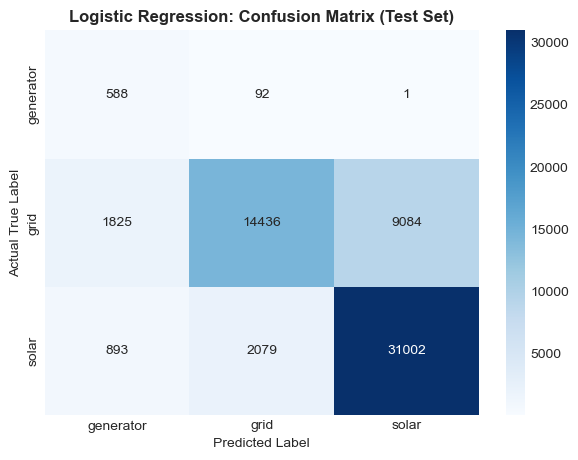

In [16]:
# CELL 7: Confusion Matrix Heatmap for Logistic Regression
import seaborn as sns
import matplotlib.pyplot as plt

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_lr, annot=True, fmt='d', cmap='Blues',
    xticklabels=le.classes_, yticklabels=le.classes_
)
plt.title("Logistic Regression: Confusion Matrix (Test Set)", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("Actual True Label")
plt.show()

In [17]:
# CELL 8: Model 2 - Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Train an ensemble of 100 decision trees
# n_jobs=-1 utilizes all available CPU cores to accelerate training
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest Classifier on 240,000 readings...")
rf_model.fit(X_train, y_train)

# Predict on unseen test data
y_pred_rf = rf_model.predict(X_test)

print("\n--- Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf, target_names=le.classes_, digits=4))

Training Random Forest Classifier on 240,000 readings...

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

   generator     0.6989    0.6476    0.6723       681
        grid     0.8470    0.8486    0.8478     25345
       solar     0.8907    0.8908    0.8908     33974

    accuracy                         0.8702     60000
   macro avg     0.8122    0.7957    0.8036     60000
weighted avg     0.8701    0.8702    0.8701     60000



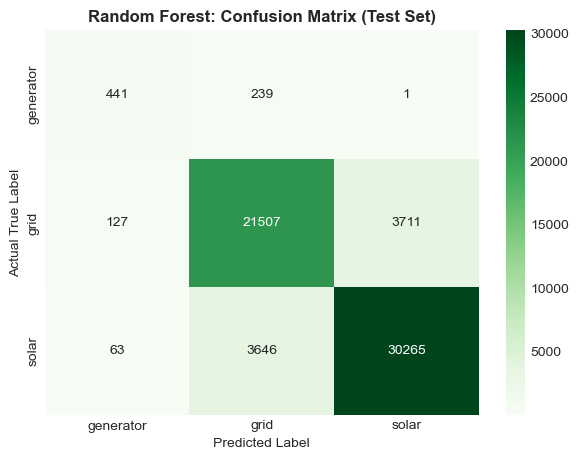

In [18]:
# CELL 9: Confusion Matrix Heatmap for Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_rf, annot=True, fmt='d', cmap='Greens',
    xticklabels=le.classes_, yticklabels=le.classes_
)
plt.title("Random Forest: Confusion Matrix (Test Set)", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("Actual True Label")
plt.show()

In [19]:
# CELL 10: Model 3 - LightGBM Classifier
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix

# Initialize LightGBM with balanced class weights to handle the rare generator class
lgb_model = lgb.LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    num_leaves=31,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

print("Training LightGBM Classifier on 240,000 readings...")
lgb_model.fit(X_train, y_train)

# Predict on unseen test data
y_pred_lgb = lgb_model.predict(X_test)

print("\n--- LightGBM Classification Report ---")
print(classification_report(y_test, y_pred_lgb, target_names=le.classes_, digits=4))

Training LightGBM Classifier on 240,000 readings...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.038217 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2063
[LightGBM] [Info] Number of data points in the train set: 240000, number of used features: 11
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612

--- LightGBM Classification Report ---
              precision    recall  f1-score   support

   generator     0.5912    0.7709    0.6692       681
        grid     0.8486    0.8490    0.8488     25345
       solar     0.8931    0.8873    0.8902     33974

    accuracy                         0.8698     60000
   macro avg     0.7776    0.8357    0.8027     60000
weighted avg     0.8709    0.8698    0.8702     60000



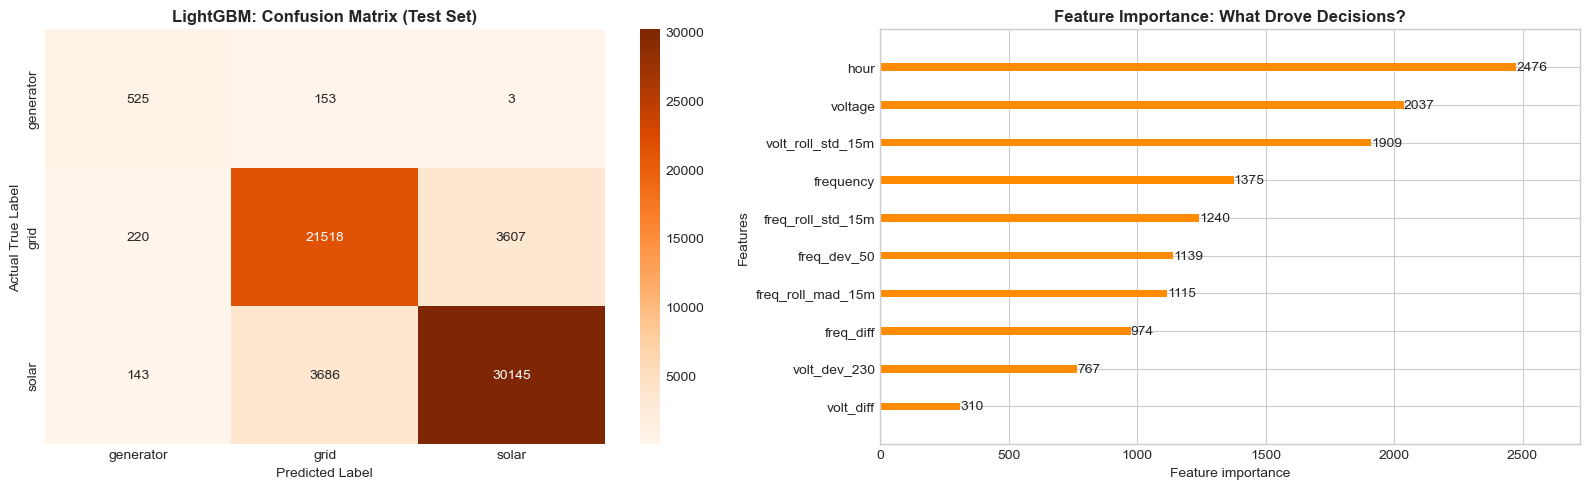

In [20]:
# CELL 11: Confusion Matrix & Feature Importance for LightGBM
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Confusion Matrix Heatmap
cm_lgb = confusion_matrix(y_test, y_pred_lgb)
sns.heatmap(
    cm_lgb, annot=True, fmt='d', cmap='Oranges',
    xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[0]
)
axes[0].set_title("LightGBM: Confusion Matrix (Test Set)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual True Label")

# 2. Feature Importance Plot (Shows which engineered features mattered most!)
lgb.plot_importance(lgb_model, max_num_features=10, ax=axes[1], color='darkorange')
axes[1].set_title("Feature Importance: What Drove Decisions?", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [21]:
# CELL 12: Enhanced Features (Grid Metadata + 1-Hour Window)
print("Adding hardware metadata and 1-hour rolling features...")

# 1. Hardware Metadata: Does this room physically have a grid connection?
active_df['has_grid_avail'] = active_df['available_power_sources'].str.lower().str.contains('grid').astype(int)

# 2. 1-Hour Rolling Window (30 readings * 2 minutes = 60 minutes)
WINDOW_1H = 30

active_df['freq_roll_std_1h'] = (
    active_df.groupby('respondent_id')['frequency']
    .rolling(window=WINDOW_1H, min_periods=5)
    .std()
    .reset_index(level=0, drop=True)
)

active_df['freq_roll_mad_1h'] = (
    (active_df['frequency'] - active_df['frequency'].mean()).abs()
    .groupby(active_df['respondent_id'])
    .rolling(window=WINDOW_1H, min_periods=5)
    .mean()
    .reset_index(level=0, drop=True)
)

# Backfill initial NaN rows
new_cols = ['has_grid_avail', 'freq_roll_std_1h', 'freq_roll_mad_1h']
active_df[new_cols] = active_df.groupby('respondent_id')[new_cols].bfill()
active_df[new_cols] = active_df[new_cols].fillna(0.0)

print("Enhanced feature engineering complete!")

Adding hardware metadata and 1-hour rolling features...
Enhanced feature engineering complete!


In [22]:
# CELL 13: Site-Based Held-Out Split
# We train on 4 facilities and test on 2 completely unseen facilities!
print("Hospital sites available:", active_df['site_id'].unique())

train_sites = ['princess_christian', 'ola_during', 'masanga', 'kambia']
test_sites = ['kabala', 'bonthe']

feature_cols_v2 = [
    'frequency', 'voltage', 
    'freq_dev_50', 'volt_dev_230', 
    'hour', 'has_grid_avail',
    'freq_diff', 'volt_diff', 
    'freq_roll_std_15m', 'freq_roll_mad_15m',
    'freq_roll_std_1h', 'freq_roll_mad_1h'
]

train_mask = active_df['site_id'].isin(train_sites)
test_mask = active_df['site_id'].isin(test_sites)

X_train_site = active_df.loc[train_mask, feature_cols_v2]
y_train_site = active_df.loc[train_mask, 'target_encoded']

X_test_site = active_df.loc[test_mask, feature_cols_v2]
y_test_site = active_df.loc[test_mask, 'target_encoded']

print(f"\nTrain set (4 hospitals): {len(X_train_site):,} readings")
print(f"Test set  (2 hospitals): {len(X_test_site):,} readings")

Hospital sites available: <StringArray>
['ola_during', 'princess_christian', 'bonthe', 'kambia', 'masanga', 'kabala']
Length: 6, dtype: str

Train set (4 hospitals): 4,231,217 readings
Test set  (2 hospitals): 881,024 readings


In [23]:
# CELL 14: Train HistGradientBoosting on Held-Out Sites
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix
import time

hgb_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.08,
    class_weight='balanced',
    random_state=42
)

print("Training HistGradientBoosting across full hospital dataset...")
t0 = time.time()
hgb_model.fit(X_train_site, y_train_site)
fit_time = time.time() - t0

y_pred_hgb = hgb_model.predict(X_test_site)

print(f"\nTraining completed in {fit_time:.1f} seconds!")
print("\n--- HistGradientBoosting Classification Report (Held-Out Sites) ---")


Training HistGradientBoosting across full hospital dataset...

Training completed in 274.2 seconds!

--- HistGradientBoosting Classification Report (Held-Out Sites) ---


In [24]:
print("Unique classes in Training Set:", np.unique(y_train_site))
print("Unique classes in Test Set:    ", np.unique(y_test_site))
print("Class names mapping:           ", dict(enumerate(le.classes_)))

Unique classes in Training Set: [0 1 2]
Unique classes in Test Set:     [0 2]
Class names mapping:            {0: 'generator', 1: 'grid', 2: 'solar'}


In [25]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Automatically find which classes actually appear in y_test_site and y_pred_hgb
present_classes = np.unique(np.concatenate([y_test_site, y_pred_hgb]))
present_names = [le.classes_[i] for i in present_classes]

print("--- HistGradientBoosting Classification Report (Held-Out Sites) ---")
print(classification_report(
    y_test_site, 
    y_pred_hgb, 
    labels=present_classes,
    target_names=present_names, 
    digits=4,
    zero_division=0
))

--- HistGradientBoosting Classification Report (Held-Out Sites) ---
              precision    recall  f1-score   support

   generator     0.9389    0.9913    0.9644    168757
       solar     0.9979    0.9847    0.9913    712267

    accuracy                         0.9860    881024
   macro avg     0.9684    0.9880    0.9778    881024
weighted avg     0.9866    0.9860    0.9861    881024



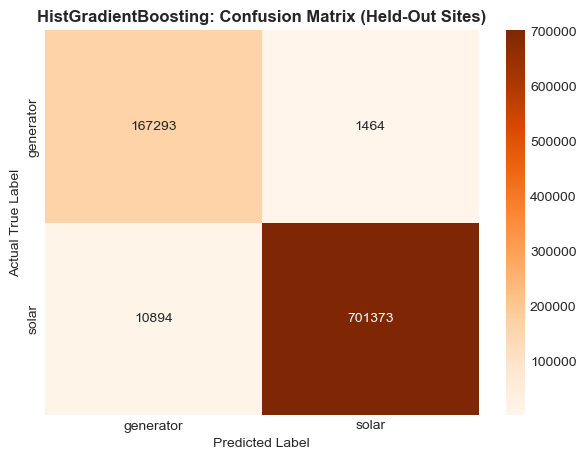

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_hgb = confusion_matrix(y_test_site, y_pred_hgb, labels=present_classes)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_hgb, annot=True, fmt='d', cmap='Oranges',
    xticklabels=present_names, yticklabels=present_names
)
plt.title("HistGradientBoosting: Confusion Matrix (Held-Out Sites)", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("Actual True Label")
plt.show()

In [27]:
# CELL 15: Interchanged Site Split (Testing on PCMH & Kambia)
print("Unique hospitals available:", active_df['site_id'].unique())

# New split: Train on 4 mixed facilities (including rural off-grid), test on 2 facilities with full grid access
train_sites_v2 = ['ola_during', 'masanga', 'kabala', 'bonthe']
test_sites_v2 = ['princess_christian', 'kambia']

train_mask_v2 = active_df['site_id'].isin(train_sites_v2)
test_mask_v2 = active_df['site_id'].isin(test_sites_v2)

X_train_v2 = active_df.loc[train_mask_v2, feature_cols_v2]
y_train_v2 = active_df.loc[train_mask_v2, 'target_encoded']

X_test_v2 = active_df.loc[test_mask_v2, feature_cols_v2]
y_test_v2 = active_df.loc[test_mask_v2, 'target_encoded']

print(f"\nTrain set ({len(train_sites_v2)} hospitals): {len(X_train_v2):,} readings")
print(f"Test set  ({len(test_sites_v2)} hospitals): {len(X_test_v2):,} readings")

# Verify that all 3 classes exist in both sets
print("\nClasses in Train set:", [le.classes_[i] for i in np.unique(y_train_v2)])
print("Classes in Test set: ", [le.classes_[i] for i in np.unique(y_test_v2)])

Unique hospitals available: <StringArray>
['ola_during', 'princess_christian', 'bonthe', 'kambia', 'masanga', 'kabala']
Length: 6, dtype: str

Train set (4 hospitals): 2,908,161 readings
Test set  (2 hospitals): 2,204,080 readings

Classes in Train set: ['generator', 'grid', 'solar']
Classes in Test set:  ['generator', 'grid', 'solar']


In [28]:
# CELL 16: Train HistGradientBoosting on the New Site Split
import time
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix

hgb_interchanged = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.08,
    class_weight='balanced',
    random_state=42
)

print("Training HistGradientBoosting on the interchanged split...")
t0 = time.time()
hgb_interchanged.fit(X_train_v2, y_train_v2)
train_time = time.time() - t0
print(f"Training completed in {train_time:.1f} seconds!")

# Predict on PCMH & Kambia test set
y_pred_v2 = hgb_interchanged.predict(X_test_v2)

print("\n--- Classification Report: Tested on PCMH & Kambia (All 3 Classes) ---")
print(classification_report(y_test_v2, y_pred_v2, target_names=le.classes_, digits=4))

Training HistGradientBoosting on the interchanged split...
Training completed in 146.6 seconds!

--- Classification Report: Tested on PCMH & Kambia (All 3 Classes) ---
              precision    recall  f1-score   support

   generator     0.9727    0.9707    0.9717    185486
        grid     0.9594    0.9562    0.9578   1383948
       solar     0.9086    0.9158    0.9122    634646

    accuracy                         0.9458   2204080
   macro avg     0.9469    0.9476    0.9472   2204080
weighted avg     0.9459    0.9458    0.9458   2204080



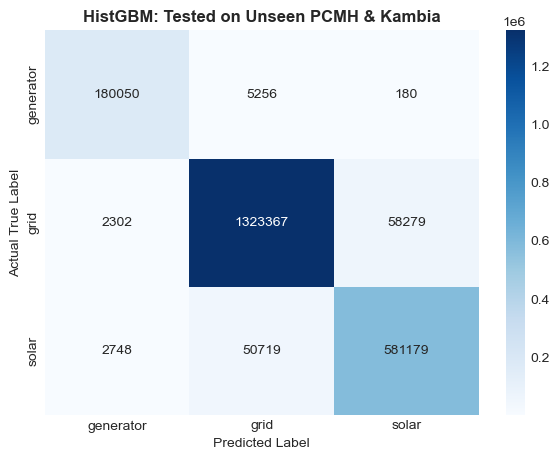

In [29]:
# CELL 17: Confusion Matrix Heatmap for PCMH & Kambia Split
import matplotlib.pyplot as plt
import seaborn as sns

cm_v2 = confusion_matrix(y_test_v2, y_pred_v2)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_v2, annot=True, fmt='d', cmap='Blues',
    xticklabels=le.classes_, yticklabels=le.classes_
)
plt.title("HistGBM: Tested on Unseen PCMH & Kambia", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("Actual True Label")
plt.show()

--- Estimated Operational Hours per Hospital (Test Sites) ---
predicted_source    generator      grid     solar
site_id                                          
kambia                6029.43      0.07  18418.93
princess_christian     140.57  45978.00   2902.33


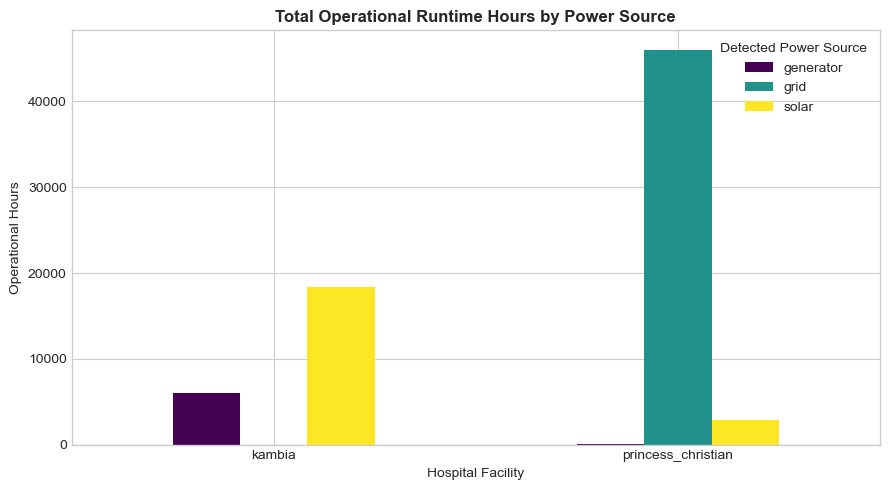

In [30]:
# CELL 18: Downstream Deliverable - Operational Hours per Hospital
# Add predicted labels to the test split DataFrame
test_results_df = active_df.loc[test_mask_v2].copy()
test_results_df['predicted_source'] = le.inverse_transform(y_pred_v2)

# Aggregate interval counts and compute operational hours (each row = 2 minutes)
runtime_summary = test_results_df.groupby(['site_id', 'predicted_source']).size().unstack(fill_value=0)
runtime_hours = (runtime_summary * 2 / 60).round(2)

print("--- Estimated Operational Hours per Hospital (Test Sites) ---")
print(runtime_hours)

# Visualize operational hours across facilities
runtime_hours.plot(kind='bar', figsize=(9, 5), colormap='viridis')
plt.title("Total Operational Runtime Hours by Power Source", fontsize=12, fontweight='bold')
plt.xlabel("Hospital Facility")
plt.ylabel("Operational Hours")
plt.xticks(rotation=0)
plt.legend(title="Detected Power Source")
plt.tight_layout()
plt.show()

In [31]:
# CELL 19: Implementing the Hybrid Architecture
def hybrid_predict_pipeline(df_subset, model, feature_cols, label_encoder):
    predictions = []
    
    # Precompute ML predictions for the entire block
    ml_preds = model.predict(df_subset[feature_cols])
    ml_labels = label_encoder.inverse_transform(ml_preds)
    
    # Iterate through physics-based deterministic overrides
    for idx, (_, row) in enumerate(df_subset.iterrows()):
        avail = str(row['available_power_sources']).lower()
        
        # Rule 1: Hardware physical constraints (Rooms with only 1 source)
        if avail == 'solar':
            predictions.append('solar')
        elif avail == 'generator':
            predictions.append('generator')
        else:
            # Ambiguous multi-source rooms fall back to ML
            predictions.append(ml_labels[idx])
            
    return pd.Series(predictions, index=df_subset.index)

# Run hybrid prediction on test data
test_hybrid_preds = hybrid_predict_pipeline(test_results_df, hgb_interchanged, feature_cols_v2, le)

# Compare accuracy of Hybrid vs Pure ML
true_labels = test_results_df['active_power_source']
hybrid_acc = (test_hybrid_preds == true_labels).mean()
print(f"Pure ML Model Accuracy: {classification_report(y_test_v2, y_pred_v2, output_dict=True)['accuracy']:.4f}")
print(f"Hybrid Pipeline Accuracy: {hybrid_acc:.4f}")

Pure ML Model Accuracy: 0.9458
Hybrid Pipeline Accuracy: 0.9467


In [33]:
# CELL 20: Vectorized Temporal Smoothing (Eliminates isolated 2-min flickers)
import pandas as pd
from sklearn.metrics import classification_report

print("Applying temporal smoothing to hybrid predictions...")

# Create a clean working DataFrame
smooth_df = pd.DataFrame({
    'respondent_id': test_results_df['respondent_id'].values,
    'pred': test_hybrid_preds.values
})

# Look at 1 step behind and 1 step ahead within the same sensor stream
prev_pred = smooth_df.groupby('respondent_id')['pred'].shift(1)
next_pred = smooth_df.groupby('respondent_id')['pred'].shift(-1)

# Condition: If isolated between identical neighbors (e.g., A -> B -> A), smooth B to A
flicker_mask = (prev_pred == next_pred) & (prev_pred.notna()) & (smooth_df['pred'] != prev_pred)

smooth_df['smoothed_pred'] = smooth_df['pred']
smooth_df.loc[flicker_mask, 'smoothed_pred'] = prev_pred[flicker_mask]

num_flickers_removed = flicker_mask.sum()
print(f"Isolated 2-minute flickers smoothed: {num_flickers_removed:,}")

# Evaluate accuracy after smoothing
smoothed_acc = (smooth_df['smoothed_pred'].values == true_labels.values).mean()
print(f"Pure ML Accuracy:     {classification_report(y_test_v2, y_pred_v2, output_dict=True)['accuracy']:.4f}")
print(f"Hybrid Accuracy:      {hybrid_acc:.4f}")
print(f"Post-Smoothed Acc:    {smoothed_acc:.4f}")

Applying temporal smoothing to hybrid predictions...


Isolated 2-minute flickers smoothed: 28,324
Pure ML Accuracy:     0.9458
Hybrid Accuracy:      0.9467
Post-Smoothed Acc:    0.9511
